# P5 — Deteksi Tepi (SIMUTEH)
**Muhammad Imam Faisal — NIM 2330511016 — Kelas 7A — SEED 1016**

Bagian 1: gradien citra dan operator tepi. Bagian 2: algoritma Canny dan keputusan pemakaian tepi.
Notebook ini harus berjalan dengan *Restart & Run All*. Semua tabel CSV dan gambar disimpan di `../hasil/`.

## Bagian 1. Gradien Citra dan Operator Tepi
### Kode 1.1 Persiapan: modul, data, praproses, dan tepi acuan

versi: 4.12.0 2.2.6 3.0.3
{'sehat': 20, 'ringan': 20, 'berat': 20} {'normal': 12, 'gelap': 12, 'terang': 12, 'kontras_rendah': 12, 'bayangan': 12}


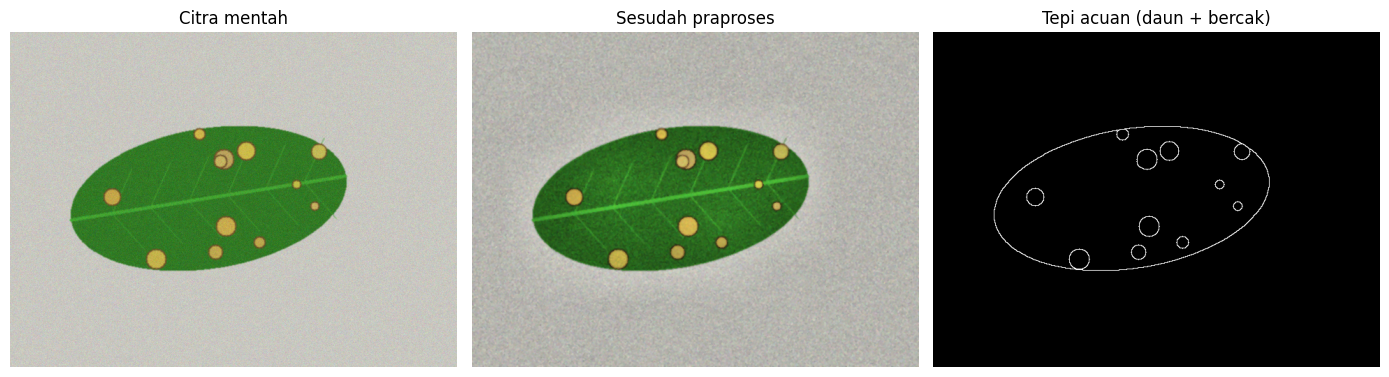

In [17]:
import sys, os, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

os.makedirs("../hasil", exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json"))   # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")
print("versi:", cv2.__version__, np.__version__, pd.__version__)
print(label.kelas.value_counts().to_dict(), label.kondisi_cahaya.value_counts().to_dict())

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])

### Verifikasi Lembar Hitung 1.1
Hitungan manual di lampiran dicek ulang dengan `cv2.filter2D` (korelasi).

In [18]:
A = np.array([[52, 55, 180], [50, 58, 185], [54, 60, 190]], np.float32)
K = {"Sobel": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32),
     "Prewitt": np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)}
for nm, kx in K.items():
    gx = cv2.filter2D(A, -1, kx)[1, 1]; gy = cv2.filter2D(A, -1, kx.T)[1, 1]
    print(f"{nm:8s} Gx={gx:.0f} Gy={gy:.0f} |G|={np.hypot(gx, gy):.2f} "
          f"|Gx|+|Gy|={abs(gx) + abs(gy):.0f} theta={np.degrees(np.arctan2(gy, gx)):.2f} deg")
lap = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], np.float32)
print("Laplacian pusat A =", cv2.filter2D(A, -1, lap)[1, 1])

Sobel    Gx=534 Gy=22 |G|=534.45 |Gx|+|Gy|=556 theta=2.36 deg
Prewitt  Gx=399 Gy=17 |G|=399.36 |Gx|+|Gy|=416 theta=2.44 deg
Laplacian pusat A = 118.0


### Kode 1.2 Gradien Sobel manual: Gx, Gy, magnitudo, dan arah

selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 584.5


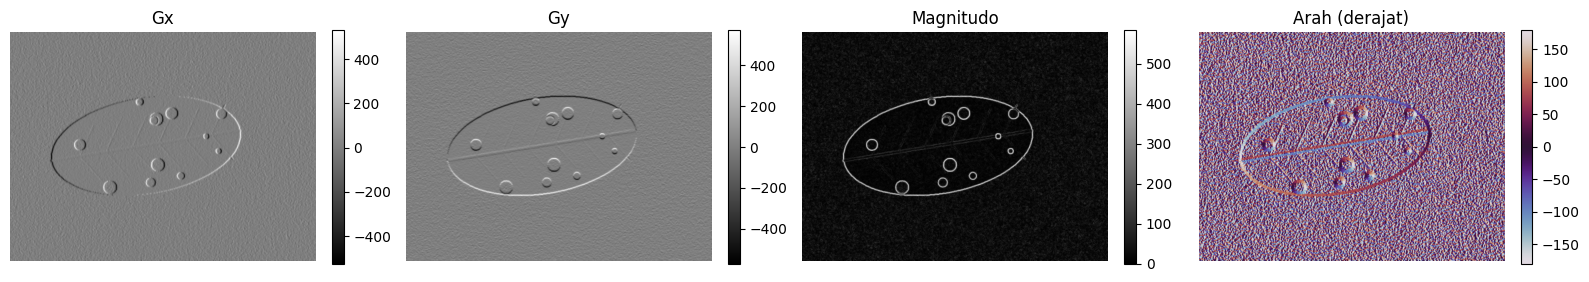

In [19]:
g = pra[:, :, 2].astype(np.float32)                   # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx)                  # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky)                  # turunan arah y (tepi horizontal)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))

# bandingkan dengan fungsi pustaka
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))

plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah, "Arah (derajat)")]):
    plt.subplot(1, 4, i + 1); plt.imshow(c, cmap="twilight" if i == 3 else "gray")
    plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)
plt.tight_layout(); plt.savefig("../hasil/p5_gradien_sobel.png", dpi=120); plt.show()

### Kode 1.3 Fungsi Sobel, Prewitt, LoG, dan Canny serta perbandingannya

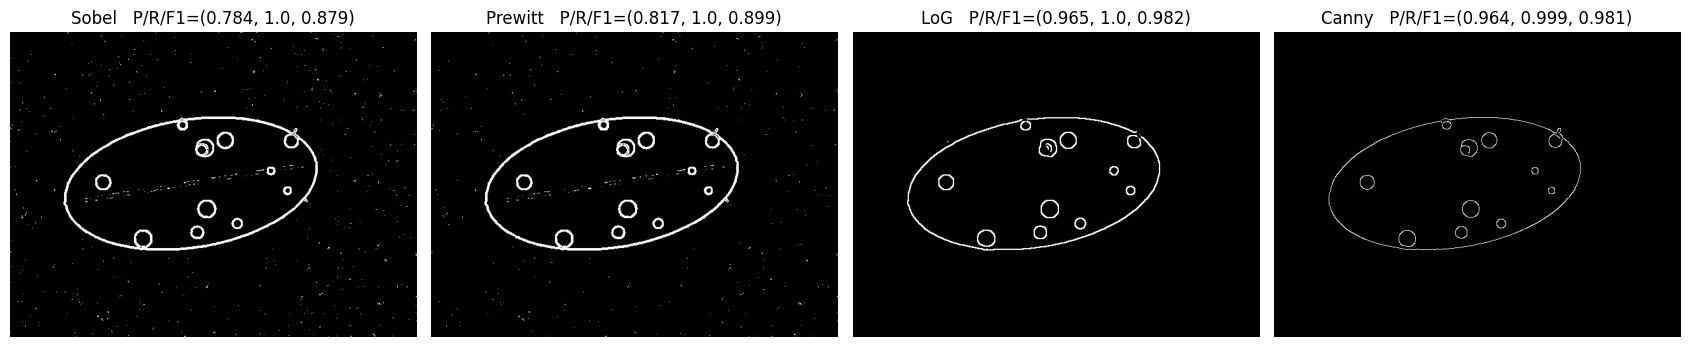

In [20]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma), cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) * 255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log, "Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm}   P/R/F1={skor_tepi(e, acuan)}" for nm, e in hasil.items()],
       ukuran=(17, 3.6))
plt.savefig("../hasil/p5_empat_operator.png", dpi=120, bbox_inches="tight")

### Kode 1.4 Tabel presisi, recall, dan F1 tepi (40 citra berbercak)

In [21]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), ("R", im[:, :, 2])]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])
tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3)
print(ringkas)
tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.733  0.748  0.737
                LoG      0.623  0.997  0.757
                Prewitt  0.804  0.956  0.862
                Sobel    0.777  0.964  0.848
          R     Canny    0.983  0.981  0.981
                LoG      0.897  0.997  0.940
                Prewitt  0.583  0.995  0.690
                Sobel    0.515  0.996  0.627
praproses Gray  Canny    0.670  0.952  0.780
                LoG      0.539  0.997  0.690
                Prewitt  0.565  0.996  0.710
                Sobel    0.532  0.996  0.681
          R     Canny    0.943  0.989  0.964
                LoG      0.809  0.997  0.879
                Prewitt  0.461  0.997  0.592
                Sobel    0.415  0.997  0.548


#### Tabel 6. Rerata F1 tepi per operator, kanal, dan sumber citra

In [22]:
tabel6 = (tabel_tepi.groupby(["metode", "sumber", "kanal"]).F1.mean().unstack(["sumber", "kanal"])
          .reindex(["Sobel", "Prewitt", "LoG", "Canny"]).round(3))
tabel6.columns = [f"{s}, {k}" for s, k in tabel6.columns]
tabel6.index = ["Sobel (T = 100)", "Prewitt (T = 75)", "LoG (sigma 3)", "Canny (30/90, sigma 2)"]
tabel6.to_csv("../hasil/p5_tabel6_f1.csv")
tabel6

,"mentah, Gray","mentah, R","praproses, Gray","praproses, R"
Sobel (T = 100),0.848,0.627,0.681,0.548
Prewitt (T = 75),0.862,0.690,0.710,0.592
LoG (sigma 3),0.757,0.940,0.690,0.879
"Canny (30/90, sigma 2)",0.737,0.981,0.780,0.964


#### Bahan P1.4: selisih P dan R (praproses − mentah)
Nilai negatif berarti praproses justru menurunkan presisi atau recall.

In [23]:
delta = (ringkas.xs("praproses") - ringkas.xs("mentah")).round(3)
delta

P      R     F1
kanal metode                      
Gray  Canny   -0.063  0.204  0.043
      LoG     -0.084  0.000 -0.067
      Prewitt -0.239  0.040 -0.152
      Sobel   -0.245  0.032 -0.167
R     Canny   -0.040  0.008 -0.017
      LoG     -0.088  0.000 -0.061
      Prewitt -0.122  0.002 -0.098
      Sobel   -0.100  0.001 -0.079

### Langkah 1.5 (Kerjakan sendiri) Grafik F1 per kondisi cahaya
Kanal R sesudah praproses, empat operator.

metode          Sobel  Prewitt    LoG  Canny
kondisi                                     
bayangan        0.472    0.518  0.952  0.988
gelap           0.363    0.411  0.971  0.974
kontras_rendah  0.680    0.736  0.714  0.980
normal          0.584    0.617  0.941  0.940
terang          0.640    0.681  0.814  0.937


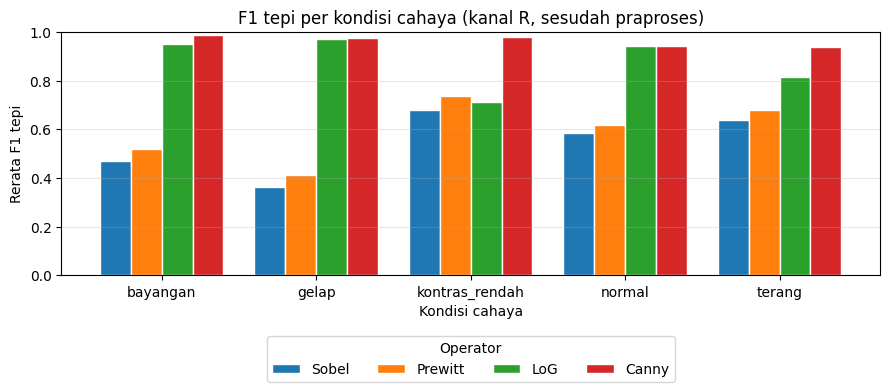

In [24]:
sub = tabel_tepi[(tabel_tepi.sumber == "praproses") & (tabel_tepi.kanal == "R")]
f1_kondisi = sub.pivot_table(index="kondisi", columns="metode", values="F1", aggfunc="mean")
f1_kondisi = f1_kondisi[["Sobel", "Prewitt", "LoG", "Canny"]]
print(f1_kondisi.round(3))

ax = f1_kondisi.plot(kind="bar", figsize=(9, 4.2), width=0.8, edgecolor="white")
ax.set_ylabel("Rerata F1 tepi"); ax.set_xlabel("Kondisi cahaya"); ax.set_ylim(0, 1)
ax.set_title("F1 tepi per kondisi cahaya (kanal R, sesudah praproses)")
ax.legend(title="Operator", ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.22))
ax.grid(axis="y", alpha=0.3); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig("../hasil/p5_f1_kondisi.png", dpi=150); plt.show()

## Bagian 2. Algoritma Canny dan Keputusan Pemakaian Tepi
### Verifikasi Lembar Hitung 2.1

In [25]:
def nms_pusat(M, arah):
    """Pertahankan pusat bila >= dua tetangga searah gradien (0 deg: kiri-kanan, 90 deg: atas-bawah)."""
    t = (M[1, 0], M[1, 2]) if arah == 0 else (M[0, 1], M[2, 1])
    return "dipertahankan" if M[1, 1] >= max(t) else "ditekan"

M1 = np.array([[30, 40, 35], [90, 100, 95], [20, 30, 25]])
M2 = np.array([[50, 60, 55], [85, 80, 70], [40, 45, 50]])
for nm, M in [("M1", M1), ("M2", M2)]:
    print(nm, {a: nms_pusat(M, a) for a in (0, 90)})

def hysteresis_1d(v, lo, hi):
    v = np.array(v); kuat = v >= hi; lemah = (v >= lo) & ~kuat; tepi = kuat.copy()
    berubah = True
    while berubah:                       # rambatkan dari piksel kuat ke tetangga lemah
        berubah = False
        for i in np.where(lemah & ~tepi)[0]:
            if (i > 0 and tepi[i - 1]) or (i < len(v) - 1 and tepi[i + 1]):
                tepi[i] = True; berubah = True
    return kuat.astype(int), lemah.astype(int), tepi.astype(int)

k, l, t = hysteresis_1d([20, 60, 120, 80, 40, 90, 30], 50, 100)
print("kuat :", k); print("lemah:", l); print("tepi :", t)

M1 {0: 'dipertahankan', 90: 'dipertahankan'}
M2 {0: 'ditekan', 90: 'dipertahankan'}
kuat : [0 0 1 0 0 0 0]
lemah: [0 1 0 1 0 1 0]
tepi : [0 1 1 1 0 0 0]


### Kode 2.1 Eksperimen sigma dan ambang Canny

In [26]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1]          # recall khusus tepi bercak
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])
canny = pd.DataFrame(baris, columns=["kelas", "sigma", "ambang", "P", "R", "F1", "R_bercak"])
print(canny.groupby(["sigma", "ambang"])[["P", "R", "F1", "R_bercak"]].mean().round(3))
print(canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak").round(3))
canny.to_csv("../hasil/p5_canny_sigma_ambang.csv", index=False)

                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.509  0.993  0.612     0.972
      30/90    0.019  0.997  0.037     0.985
      50/150   0.116  0.995  0.181     0.977
1.0   100/200  0.970  0.991  0.981     0.944
      30/90    0.243  0.994  0.340     0.971
      50/150   0.824  0.993  0.886     0.969
2.0   100/200  0.790  0.789  0.790     0.729
      30/90    0.943  0.989  0.964     0.945
      50/150   0.978  0.982  0.980     0.905
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.972   0.972
      30/90    0.990   0.981
      50/150   0.980   0.975
1.0   100/200  0.968   0.919
      30/90    0.975   0.967
      50/150   0.972   0.966
2.0   100/200  0.752   0.706
      30/90    0.954   0.937
      50/150   0.926   0.884


#### Tabel 7. Eksperimen parameter Canny

In [27]:
tabel7 = canny.groupby(["sigma", "ambang"], sort=False)[["P", "R", "F1"]].mean()
rb = canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak", sort=False)
tabel7["R bercak (berat)"] = rb["berat"]; tabel7["R bercak (ringan)"] = rb["ringan"]
tabel7 = tabel7.round(3)
tabel7.to_csv("../hasil/p5_tabel7_canny.csv")
tabel7

P      R     F1  R bercak (berat)  R bercak (ringan)
sigma ambang                                                           
0.0   30/90    0.019  0.997  0.037             0.990              0.981
      50/150   0.116  0.995  0.181             0.980              0.975
      100/200  0.509  0.993  0.612             0.972              0.972
1.0   30/90    0.243  0.994  0.340             0.975              0.967
      50/150   0.824  0.993  0.886             0.972              0.966
      100/200  0.970  0.991  0.981             0.968              0.919
2.0   30/90    0.943  0.989  0.964             0.954              0.937
      50/150   0.978  0.982  0.980             0.926              0.884
      100/200  0.790  0.789  0.790             0.752              0.706

### Kode 2.2 Ambang Canny otomatis berbasis median

In [28]:
def canny_otomatis(g, s=0.33):
    """Ambang dari median intensitas: bawah = (1-s) x median, atas = (1+s) x median."""
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis", skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90", skor_tepi(tepi_canny(g), ac)[2], np.median(g)])
auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1", "median"])
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3))
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1))

kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.500  0.543           0.863   0.682   0.841
      tetap 30/90     0.773  0.732           0.913   0.730   0.748
R     otomatis        0.308  0.397           0.848   0.701   0.946
      tetap 30/90     0.988  0.974           0.980   0.940   0.937
kanal  kondisi       
Gray   bayangan          117.6
       gelap             135.2
       kontras_rendah    150.5
       normal            167.5
       terang            198.6
R      bayangan          127.0
       gelap             151.9
       kontras_rendah    154.1
       normal            175.2
       terang            200.2
Name: median, dtype: float64


### Bahan P2.3: ambang dari median vs besar gradien di tepi daun
Canny (OpenCV, `L2gradient=False`) membandingkan ambang dengan magnitudo L1 = |Gx| + |Gy| dari Sobel 3×3. Di sini dihitung rerata magnitudo itu tepat di tepi daun acuan, setelah penghalusan Gaussian sigma 2 seperti `tepi_canny`.

In [29]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    tepi_daun = tepi_acuan(md) > 0
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        gs = cv2.GaussianBlur(g, (0, 0), 2.0).astype(np.float32)
        L1 = np.abs(cv2.Sobel(gs, cv2.CV_32F, 1, 0)) + np.abs(cv2.Sobel(gs, cv2.CV_32F, 0, 1))
        v = np.median(g)
        baris.append([d.kondisi_cahaya, kanal, v, int(0.67 * v), int(min(255, 1.33 * v)),
                      np.median(L1[tepi_daun]), np.percentile(L1[tepi_daun], 90)])
grad_tepi = pd.DataFrame(baris, columns=["kondisi", "kanal", "median_intensitas", "ambang_bawah_auto",
                                         "ambang_atas_auto", "median_grad_tepi_daun", "p90_grad_tepi_daun"])
grad_tepi_ringkas = grad_tepi.groupby(["kondisi", "kanal"]).mean().round(1)
grad_tepi_ringkas.to_csv("../hasil/p5_grad_tepi_daun.csv")
grad_tepi_ringkas

median_intensitas  ambang_bawah_auto  ambang_atas_auto  median_grad_tepi_daun  p90_grad_tepi_daun
kondisi        kanal                                                                                                   
bayangan       Gray               117.6               78.4             155.9             154.199997          179.199997
               R                  127.0               84.8             168.2             217.000000          260.100006
gelap          Gray               135.2               90.1             179.4             185.000000          212.800003
               R                  151.9              101.2             201.5             267.000000          310.700012
kontras_rendah Gray               150.5              100.2             199.8             101.900002          120.800003
               R                  154.1              102.9             204.4             131.199997          154.199997
normal         Gray               167.5              111.6             222.4             176.800003          205.000000
               R                  175.2              116.8             232.8             247.199997          285.500000
terang         Gray               198.6              132.6             254.1             152.500000          176.899994
               R                  200.2              133.8             254.5             194.399994          223.600006

### Langkah 2.4 (Kerjakan sendiri) Ambang otomatis dari persentil magnitudo
1. haluskan dengan Gaussian, 2. hitung magnitudo Sobel, 3. ambang atas = persentil ke-q magnitudo dan ambang bawah = rasio × ambang atas, 4. panggil `cv2.Canny`.

Magnitudo dihitung dalam norma L1 (|Gx| + |Gy|) karena itulah yang dipakai `cv2.Canny` secara bawaan, jadi ambangnya berada pada skala yang sama.

In [30]:
def canny_persentil(g, q, rasio=0.4, sigma=2.0):
    """Canny dengan ambang dari persentil ke-q magnitudo gradien (bukan dari intensitas)."""
    gs = cv2.GaussianBlur(g, (0, 0), sigma) if sigma > 0 else g
    f = gs.astype(np.float32)
    mag = np.abs(cv2.Sobel(f, cv2.CV_32F, 1, 0)) + np.abs(cv2.Sobel(f, cv2.CV_32F, 0, 1))
    hi = float(np.percentile(mag, q))
    lo = rasio * hi
    return cv2.Canny(gs, lo, hi)

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "median (Kode 2.2)", skor_tepi(canny_otomatis(g), ac)[2]])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90", skor_tepi(tepi_canny(g), ac)[2]])
        for q in [90, 95, 98, 99]:          # 99 = tambahan, sesuai proporsi piksel tepi (~0,6%)
            baris.append([d.kondisi_cahaya, kanal, f"persentil q={q}", skor_tepi(canny_persentil(g, q), ac)[2]])
pers = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1"])
tabel_pers = pers.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3)
tabel_pers["rerata"] = pers.groupby(["kanal", "ambang"]).F1.mean().round(3)
tabel_pers.to_csv("../hasil/p5_canny_persentil.csv")
tabel_pers

kondisi                  bayangan  gelap  kontras_rendah  normal  terang  rerata
kanal ambang                                                                    
Gray  median (Kode 2.2)     0.500  0.543           0.863   0.682   0.841   0.686
      persentil q=90        0.111  0.098           0.088   0.124   0.098   0.104
      persentil q=95        0.416  0.492           0.344   0.531   0.420   0.441
      persentil q=98        0.782  0.828           0.777   0.806   0.770   0.793
      persentil q=99        0.938  0.930           0.911   0.909   0.936   0.925
      tetap 30/90           0.773  0.732           0.913   0.730   0.748   0.780
R     median (Kode 2.2)     0.308  0.397           0.848   0.701   0.946   0.640
      persentil q=90        0.098  0.086           0.091   0.101   0.093   0.094
      persentil q=95        0.303  0.226           0.296   0.460   0.448   0.347
      persentil q=98        0.990  0.986           0.911   0.982   0.922   0.958
      persentil q=99        0.987  0.987           0.980   0.982   0.982   0.983
      tetap 30/90           0.988  0.974           0.980   0.940   0.937   0.964

#### Proporsi piksel tepi acuan per citra (bahan P2.4: kaitan q dengan proporsi tepi)

In [31]:
prop = []
for _, d in label[label.kelas != "sehat"].iterrows():
    _, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    prop.append(100 * (ac > 0).mean())
print(f"piksel tepi acuan: rerata {np.mean(prop):.2f}% dari citra (min {np.min(prop):.2f}%, maks {np.max(prop):.2f}%)")
print(f"-> persentil yang sesuai kira-kira q = {100 - np.mean(prop):.1f}")

piksel tepi acuan: rerata 0.56% dari citra (min 0.39%, maks 0.74%)
-> persentil yang sesuai kira-kira q = 99.4


### Kode 2.3 Tepi palsu di bagian dalam daun sehat

kanal            Gray      R
kondisi                     
bayangan        699.2    0.0
gelap           841.0    0.0
kontras_rendah  259.0    0.0
normal          857.8    0.0
terang          875.2  227.0


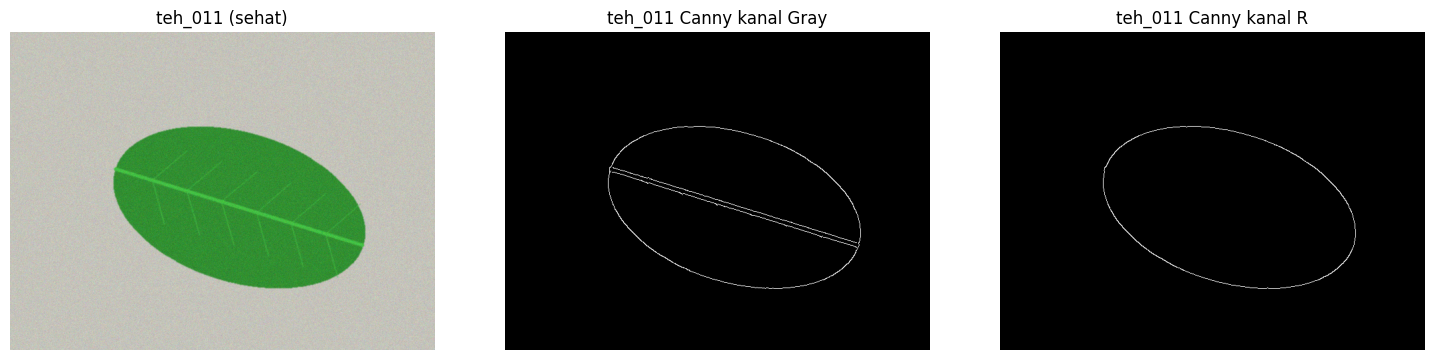

In [32]:
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0           # bagian dalam daun
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e); judul.append(f"teh_011 Canny kanal {kanal}")
sehat = pd.DataFrame(baris, columns=["kondisi", "kanal", "piksel_tepi_di_dalam_daun"])
print(sehat.pivot_table(index="kondisi", columns="kanal", values="piksel_tepi_di_dalam_daun").round(1))
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul, ukuran=(15, 3.6))
plt.savefig("../hasil/p5_tepi_daun_sehat.png", dpi=120, bbox_inches="tight")

### Langkah 2.6 (Kerjakan sendiri) Tabel 8. Keputusan pemakaian deteksi tepi pada SIMUTEH

| Keperluan | Dipakai? | Operator dan parameter | Bukti |
|---|---|---|---|
| Menemukan batas daun | Tidak memakai Canny; batas daun diambil dari gradien morfologi mask daun | `MORPH_GRADIENT` mask daun, SE elips 3×3 | Keluaran Kode 3.4: F1 gradien morfologi 0,97–0,98 pada normal/gelap vs Canny Gray 0,68–0,69 |
| Menemukan batas bercak | Ya, hanya untuk visualisasi dan pemeriksaan petugas | Canny kanal R, sigma 2, ambang tetap 30/90 atau persentil q = 98 | Tabel 6 (Canny R 0,964), Tabel 7, tabel Langkah 2.4 |
| Mengisi wilayah bercak (segmentasi) | Tidak | Ambang median + k×MAD kanal R lalu opening/closing (Bagian 3–5) | Kontur Canny tidak selalu tertutup sehingga luas tidak bisa dihitung; P2.6 |
| Fitur bentuk bercak (P9) | Ya | Kontur `cv2.findContours` dari mask bercak bersih (keliling, kebulatan, rasio aspek) | Tabel 10, diagram sebar Langkah 4.4 |

